# Fitting the condenser: three lenses, an unknown source, and what the beam at the specimen can tell

A design study, like `two_cameras_design.ipynb`: TemGym only, simulated recordings with noise, no microscope.

**The question.** The condenser has three lenses, CL1, CL2 and CL3, a source whose position and direction are not
known, and an aperture with holes of known diameter. Everything is seen from below: the beam's size, its spread of
angles, its brightness and where it lands, on the cameras. Can a recording of those find where the condenser lenses
are and how strong they are? How few frames does it take? Does the second camera help, and does it stand in for a
second high tension?

**The short answers** (each is shown below).

1. **A recording of 46 to 54 condenser settings (92 to 108 frames) gives a condenser that predicts the beam.** For
   lens values it never saw, the fitted TemGym condenser gives the beam's radius, spread of angles and brightness to
   about 1 %, and where it lands to about 1 % of its radius. Shorter recordings were tried and the fit failed on most
   of them.
2. **It pins the lower half of the condenser and not the upper half.** CL3's place comes out within a few mm, how far
   each lens turns the beam to 1 %, and the hole centres to 0.1 um. The places of CL1, CL2 and the source do not
   come out: they slide together along one family of condensers that all send the same beams to the specimen.
3. **The reason is not a lack of frames.** Nothing below the aperture can tell how big the source's angles are. A
   source twice as far away, sending out half the angles, with CL1 and CL2 moved and re-strengthened to match, gives
   the same beams. The known hole diameter is a ruler at the aperture, and it works there. The upper half needs a
   ruler of its own: if the source's spread of angles were known, every lens place would come out to about 1 mm.
4. **The second camera does not change this, and neither would a second high tension by the argument in section 2.**
   What the Merlin does add is range: it reads small angles (nearly parallel beams) four times finer than the screen
   camera. Two cameras at one projection setting cannot give the beam's radius and spread together; that still takes
   a magnification row and a camera length.
5. **The projection lenses are not fitted here, and their fitted model is not needed either.** The condenser fit
   only needs the beam in metres and radians, which the gold rings and the grating image give
   (`two_cameras_design.ipynb`, section 7).

It uses a GPU if JAX has one (about five minutes). On a CPU set `SEEDS=1`.

In [1]:
import functools, json, os, time
from pathlib import Path

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
import jax.numpy as jnp
import numpy as np
from jax.flatten_util import ravel_pytree
from scipy.optimize import least_squares

jax.config.update("jax_enable_x64", True)
from temgym_core.components import ElectromagneticLens, Plane
from temgym_core.plotting import trace_ray_paths
from temgym_core.pyjem_simulator.condenser import Condenser
from temgym_core.ray import Ray
from temgym_core.run import column_matrix

NEOARM = json.loads(Path("../virtual_neoarm/virtual_neoarm.json").read_text())
DESIGN = json.loads(Path("../virtual_neoarm/condenser.json").read_text())
VOLTAGE = 200e3
V_STAR = VOLTAGE * (1 + VOLTAGE / (2 * 510998.95))
NAMES = ["CL1", "CL2", "CL3"]

# The hidden condenser: the virtual NEOARM's (condenser.json), with a CL2 added between CL1 and CL3. The console
# holds CL2 at 0, as the real NEOARM's did on 2026-11-10, so at the console's values nothing is changed.
objective = NEOARM["lenses"]["objective"]
front_field = {"z_m": -objective["z_m"], "ampere_turns": objective["ampere_turns"], "Gc": objective["Gc"], "Tc": objective.get("Tc", 0.0)}
CONDENSER = Condenser.from_dict(DESIGN, front_field)
Z_SOURCE, Z_APERTURE = DESIGN["source"]["z_m"], DESIGN["aperture"]["z_m"]
TRUE_LENSES = {name: dict(DESIGN["lenses"][name], Tc=1e-6) for name in ("CL1", "CL3")}       # a body 2.5 mm thick at 31000
TRUE_LENSES["CL2"] = dict(z_m=-0.62, ampere_turns_per_dac=0.08, Gc=0.8, Tc=1e-6)
HOLE_RADIUS = np.array(DESIGN["aperture"]["hole_diameters_m"]) / 2                           # holes 1-4: 75, 35, 20, 5 um
EDGE = DESIGN["aperture"]["edge_m"]
# what the fit is not told: the source is off the lens axis and tilted, and no hole is centred
SOURCE = dict(x0=complex(4e-6, -3e-6), tilt=complex(3e-5, 5e-5), size=DESIGN["source"]["rms_size_m"], spread=DESIGN["source"]["rms_angle_rad"])
HOLE_CENTRE = np.array([8e-6 - 4e-6j, 5e-6 + 3e-6j, -2e-6 + 6e-6j, 1e-6 + 1e-6j])


def upper(dac):
    "The hidden condenser from the source to the aperture plane, for CL1, CL2, CL3 at these DAC values."
    parts = [ElectromagneticLens(z=TRUE_LENSES[n]["z_m"], turns=TRUE_LENSES[n]["ampere_turns_per_dac"], current=dac[i],
                                 Gc=TRUE_LENSES[n]["Gc"], Tc=TRUE_LENSES[n]["Tc"]) for i, n in enumerate(NAMES)]
    return [*parts, Plane(z=Z_APERTURE)]


# below the aperture nothing changes in TEM mode: the corrector's transfer lenses, CM and the objective's front field
LOWER = [*CONDENSER.corrector_lenses(), CONDENSER.lens("CM", CONDENSER.cm_dac), CONDENSER.front_field_lens(1.0), Plane(z=0.0)]
upper_matrix = jax.jit(jax.vmap(lambda dac: column_matrix(upper(dac), source_z=Z_SOURCE, voltage=VOLTAGE)))
LOWER_MATRIX = np.asarray(column_matrix(LOWER, source_z=Z_APERTURE, voltage=VOLTAGE))


def as_complex(m):
    "Round optics: position and slope out per position and slope in, as four complex numbers (x + iy)."
    m = np.asarray(m)
    return m[..., 0, 0] + 1j * m[..., 1, 0], m[..., 0, 2] + 1j * m[..., 1, 2], m[..., 2, 0] + 1j * m[..., 3, 0], m[..., 2, 2] + 1j * m[..., 3, 2]


print(jax.devices())
print("lens places above the aperture (mm): source 300, CL1 200, CL2 120, CL3 30")

[CudaDevice(id=0)]
lens places above the aperture (mm): source 300, CL1 200, CL2 120, CL3 30


## 1. The hidden condenser, and what one condenser setting gives

    source -> CL1 -> CL2 -> CL3 -> aperture (a hole) -> deflectors, corrector, CM, objective front field -> specimen

The source sends out a wide cone. The lenses bring it to a crossover, and the hole lets through the middle of the
cone. Below the hole nothing changes in TEM mode, so that part acts as one fixed lens.

For each condenser setting (CL1, CL2, CL3 and a hole) the recording keeps two frames:

| Frame | What is read from it |
|---|---|
| a magnification row where the beam fits the camera | the beam's rms radius at the specimen, where its middle is, and its total signal |
| a camera length where the pattern fits | the rms spread of angles, and the beam's direction |

Pixels become metres and radians through the size of a CLA1 unit and a CLA2 unit, which the gold rings and the
grating image give. Those are taken as 0.3 % wrong here, differently in each simulated recording.

**Noise.** A radius or spread is taken as good to 1 % (the real fits in `fit_predictor.ipynb` reached 1-3 %), the
signal to 2 %, the beam's middle to 0.5 % of its radius.

In [2]:
RADIUS_SCATTER, SIGNAL_SCATTER, CENTRE_SCATTER = 0.01, 0.02, 0.005

# rays for the truth: a fine grid over the hole (with its soft edge) and over the source
_rho, _w = np.polynomial.legendre.leggauss(120)
_rho, _w = (_rho + 1) / 2, _w / 2
_phi = 2 * np.pi * (np.arange(128) + 0.5) / 128
_gh, _gw = np.polynomial.hermite_e.hermegauss(5)
_gw = _gw / _gw.sum()


def true_beams(settings):
    "What the hidden condenser sends to the specimen for rows of (CL1, CL2, CL3, hole 1-4)."
    settings = np.asarray(settings, float)
    N = np.asarray(upper_matrix(jnp.array(settings[:, :3])))
    la, lb, lc, ld = as_complex(LOWER_MATRIX)
    out = []
    for (na, nb, nc, nd), hole in zip(zip(*as_complex(N)), settings[:, 3].astype(int)):
        R, h = HOLE_RADIUS[hole - 1], HOLE_CENTRE[hole - 1]
        reach = R + 6 * EDGE
        u = h + reach * _rho[:, None, None, None] * np.exp(1j * _phi[None, :, None, None])        # where a ray crosses the aperture plane
        area = (_w * _rho)[:, None, None, None] * (2 * np.pi / len(_phi)) * reach ** 2
        p = SOURCE["x0"] + SOURCE["size"] * (_gh[None, None, :, None] + 1j * _gh[None, None, None, :])   # where it left the source
        theta = (u - na * p) / nb                                                                  # so it left at this angle
        weight = (np.exp(-np.abs(theta - SOURCE["tilt"]) ** 2 / (2 * SOURCE["spread"] ** 2)) / (2 * np.pi * SOURCE["spread"] ** 2 * abs(nb) ** 2)
                  / (1 + np.exp(-(R - np.abs(u - h)) / (EDGE / 4))) * area * _gw[None, None, :, None] * _gw[None, None, None, :])
        slope = nc * p + nd * theta
        X, T = la * u + lb * slope, lc * u + ld * slope                                            # at the specimen
        total = weight.sum()
        cx, ct = (weight * X).sum() / total, (weight * T).sum() / total
        out.append([np.sqrt((weight * np.abs(X - cx) ** 2).sum() / total / 2), np.sqrt((weight * np.abs(T - ct) ** 2).sum() / total / 2), total, cx, ct])
    out = np.array(out)
    return dict(radius=out[:, 0].real, spread=out[:, 1].real, through=out[:, 2].real, centre=out[:, 3], tilt=out[:, 4])


def record(settings, rng, unit_error=0.003):
    "One simulated recording: the true beams with noise, in metres and radians (the unit sizes a little wrong)."
    true, n = true_beams(settings), len(settings)
    length, angle = 1 + rng.normal(0, unit_error), 1 + rng.normal(0, unit_error)
    noise = lambda: rng.normal(0, 1, n) + 1j * rng.normal(0, 1, n)
    return dict(radius=true["radius"] * length * (1 + RADIUS_SCATTER * rng.normal(0, 1, n)),
                spread=true["spread"] * angle * (1 + RADIUS_SCATTER * rng.normal(0, 1, n)),
                signal=true["through"] * (1 + SIGNAL_SCATTER * rng.normal(0, 1, n)),
                centre=(true["centre"] + CENTRE_SCATTER * true["radius"] * noise()) * length + (2e-7 - 1e-7j),      # where the camera's
                tilt=(true["tilt"] + CENTRE_SCATTER * true["spread"] * noise()) * angle + (3e-5 + 1e-5j))           # middle is: not known


console = [31232, 0, 33866]
print(f"{'CL1':>6} {'CL2':>6} {'CL3':>6} hole  radius (nm)  spread (urad)  let through (%)")
for cl3 in (31866, 33866, 35866, 39866):
    for hole in (2, 3):
        b = true_beams([[console[0], console[1], cl3, hole]])
        print(f"{console[0]:6d} {console[1]:6d} {cl3:6d} {hole:4d} {b['radius'][0] * 1e9:12.1f} {b['spread'][0] * 1e6:14.1f} {b['through'][0] * 100:16.2f}")

   CL1    CL2    CL3 hole  radius (nm)  spread (urad)  let through (%)


 31232      0  31866    2        323.7         1600.5            26.77
 31232      0  31866    3        189.6          937.6             9.09
 31232      0  33866    2         37.0         1477.5            29.08
 31232      0  33866    3         21.7          867.4             9.91
 31232      0  35866    2        454.9         1334.7            31.82
 31232      0  35866    3        267.8          785.7            10.89
 31232      0  39866    2       1510.9          972.3            38.95
 31232      0  39866    3        895.8          576.5            13.58


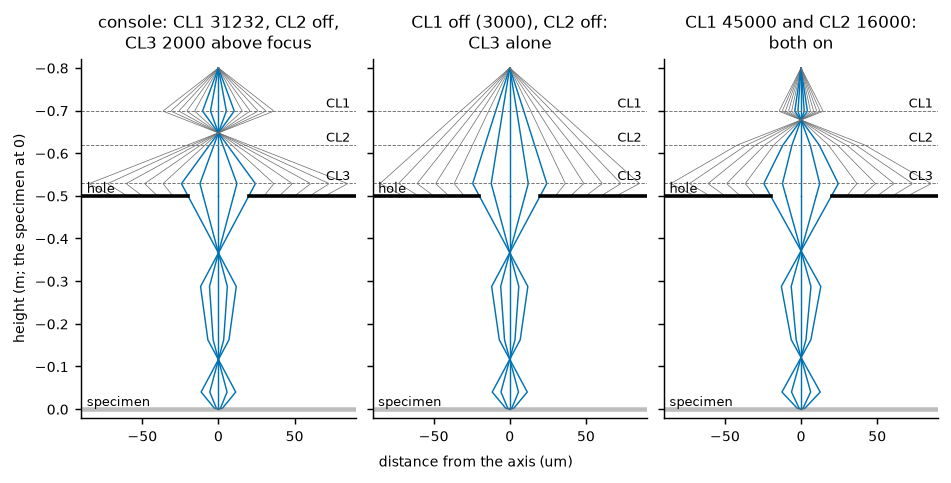

In [3]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#6E6E6E"

figure, panels = plt.subplots(1, 3, figsize=(7.2, 3.6), constrained_layout=True, sharey=True)
pictures = [("console: CL1 31232, CL2 off,\nCL3 2000 above focus", [31232, 0, 35680]), ("CL1 off (3000), CL2 off:\nCL3 alone", [3000, 0, 29240]),
            ("CL1 45000 and CL2 16000:\nboth on", [45000, 16000, 32360])]
for panel, (title, dac) in zip(panels, pictures):
    na, nb, nc, nd = as_complex(np.asarray(upper_matrix(jnp.array([dac], float)))[0])
    edge = HOLE_RADIUS[2] / abs(nb)                                              # the angle at the source that reaches the edge of the 40 um hole
    angles = jnp.array(np.linspace(-3.5, 3.5, 15) * edge)
    rays = Ray(x=jnp.zeros(15), y=jnp.zeros(15), dx=angles, dy=jnp.zeros(15), z=jnp.full(15, Z_SOURCE), pathlength=jnp.zeros(15), voltage=VOLTAGE)
    z, x = trace_ray_paths([*upper(jnp.array(dac, float))[:-1], Plane(z=Z_APERTURE), *LOWER], rays, ray_coordinate="x_rot")
    z, x = np.asarray(z), np.asarray(x) * 1e6
    above = z <= Z_APERTURE
    for ray in range(15):
        through = abs(np.linspace(-3.5, 3.5, 15)[ray]) <= 1
        panel.plot(x[above, ray], z[above], color=BLUE if through else GREY, lw=0.8 if through else 0.4)
        if through:
            panel.plot(x[z >= Z_APERTURE, ray], z[z >= Z_APERTURE], color=BLUE, lw=0.8)
    for name in NAMES:
        panel.axhline(TRUE_LENSES[name]["z_m"], color=GREY, lw=0.5, ls="--")
        panel.annotate(name, (0.98, TRUE_LENSES[name]["z_m"]), xycoords=("axes fraction", "data"), ha="right", va="bottom", fontsize=7)
    panel.plot([-90, -20], [Z_APERTURE] * 2, color="black", lw=2), panel.plot([20, 90], [Z_APERTURE] * 2, color="black", lw=2)
    panel.annotate("hole", (0.02, Z_APERTURE), xycoords=("axes fraction", "data"), va="bottom", fontsize=7)
    panel.axhline(0.0, color=GREY, lw=2.5, alpha=0.45)
    panel.annotate("specimen", (0.02, 0.0), xycoords=("axes fraction", "data"), va="bottom", fontsize=7)
    panel.set(title=title, xlim=(-90, 90), ylim=(0.02, Z_SOURCE - 0.02))
panels[0].set_ylabel("height (m; the specimen at 0)")
figure.supxlabel("distance from the axis (um)", fontsize=8)
plt.show()

**Figure 1, rays through the hidden condenser** (TemGym's traced paths, the turning of the lenses undone). Blue rays
pass the 40 um hole, grey rays are stopped. The three settings send nearly the same beam to the specimen with very
different lens values: what reaches the specimen is set by where the crossover is and how wide the cone is at the
hole, and several lens settings give the same two things. That is why the specimen alone has trouble telling where the
upper lenses are.

## 2. What the second camera adds, and what it does not

Three questions, answered with the virtual NEOARM's projection lenses.

**Can both cameras, at one projection setting, give the beam's radius and its spread of angles together?** That
would halve the frames and never change a projection lens. **No.** Two cameras 0.45 m apart, each reading a size to
0.1 px, tell a ray's position and slope after the last lens only so finely, and no lens setting changes how much of
that fineness the beam fills. For a beam of 1 um and 1 mrad: if one of the two is read to 1 %, the other is unknown
by more than ten times its own size, whatever the lens values. The table below tries six projection settings. A
magnification row gives the radius to 0.2 % and a camera length gives the spread to 1.7 %, each on its own frame.

**What does the Merlin add, then?** Range at small angles. At the longest camera length one Merlin pixel is 12.5
urad against 55 urad on the screen camera, so a nearly parallel beam (a spread near 0.1 mrad) is still 8 px wide
there. The screen camera's field is eight times wider, so it takes the large beams.

**Does it stand in for a second high tension?** For the projection lenses, yes (`two_cameras_design.ipynb`). For the
condenser, neither would give what is missing. Changing the high tension changes every lens strength by one known
factor, which for the lenses above the aperture is the same as changing their currents, and the recording already
does that. It would add one thing: a lens body's thickness does not follow the high tension while its strength does,
and the thickness is part of what lets the upper lenses slide (section 5). That is an argument, not tested here.

In [4]:
PROJECTION = ["IL1", "IL2", "IL3", "PL1"]
PIXEL, FRAME_PX, SEPARATION = np.array([110e-6, 55e-6]), np.array([479, 256]), 0.45


def projection(dac):
    lens = lambda n: NEOARM["lenses"][n]
    parts = [ElectromagneticLens(z=objective["z_m"], turns=objective["ampere_turns"], current=1.0, Gc=objective["Gc"])]
    parts += [ElectromagneticLens(z=lens(n)["z_m"], turns=lens(n)["ampere_turns_per_dac"], current=dac[i], Gc=lens(n)["Gc"], Tc=lens(n)["Tc"])
              for i, n in enumerate(PROJECTION)]
    return [*parts, Plane(z=NEOARM["camera_z_m"])]


projection_matrix = jax.jit(jax.vmap(lambda dac: column_matrix(projection(dac), voltage=VOLTAGE)))


def on_cameras(dacs):
    "Metres on [screen camera, Merlin] per metre (A) and per radian (B) at the specimen, for rows of IL1-PL1 values."
    a, b, c, d = as_complex(np.asarray(projection_matrix(jnp.array(dacs, float))))
    return np.stack([a, a + SEPARATION * c], 1), np.stack([b, b + SEPARATION * d], 1)


rows = {mode: sorted((float(label), [dac[n] for n in PROJECTION]) for label, dac in NEOARM["lens_table"][mode].items()) for mode in ("MAG", "DIFF")}
A, _ = on_cameras([dac for _, dac in rows["MAG"]])
_, B = on_cameras([dac for _, dac in rows["DIFF"]])
print("what each camera can measure (a beam between 8 px rms and a fifth of the frame):")
for camera, name in enumerate(["screen camera", "Merlin"]):
    smallest, largest = 8 * PIXEL[camera], 0.2 * FRAME_PX[camera] * PIXEL[camera]
    print(f"   {name:14s} radius from {smallest / abs(A[-1, camera]) * 1e9:5.1f} nm to {largest / abs(A[0, camera]) * 1e9:5.0f} nm"
          f"     spread of angles from {smallest / abs(B[-1, camera]) * 1e6:4.0f} urad to {largest / abs(B[0, camera]) * 1e3:4.1f} mrad")

radius, spread = 1e-6, 1e-3
trial = {"MAG 8000": rows["MAG"][0][1], "DIFF 0.4 m": dict(rows["DIFF"])[0.4], "MAG 8000, PL1 at 12000": [*rows["MAG"][0][1][:3], 12000],
         "DIFF 0.4 m, PL1 at 12000": [*dict(rows["DIFF"])[0.4][:3], 12000], "all four weak": [3000] * 4, "IL1 at 42000, rest weak": [42000, 3000, 3000, 3000]}
print(f"\none projection setting, both cameras, a beam of {radius * 1e6:.0f} um and {spread * 1e3:.0f} mrad, each size read to 0.1 px:")
print(f"   {'projection setting':26s} {'size on the cameras (px)':>26s}   radius known to   spread known to")
for name, dac in trial.items():
    a, b = on_cameras([dac])
    M = []
    for camera in (0, 1):                                                        # the turning of the lenses taken out
        turn = np.exp(-1j * np.angle(a[0, camera] if abs(a[0, camera]) * radius > abs(b[0, camera]) * spread else b[0, camera]))
        M.append([(a[0, camera] * turn).real, (b[0, camera] * turn).real])
    M = np.array(M)
    size = np.abs(M @ [radius, spread]) / PIXEL
    errors = np.linalg.inv(M) @ np.diag((0.1 * PIXEL) ** 2) @ np.linalg.inv(M).T
    print(f"   {name:26s} {size[0]:12.1f} {size[1]:12.1f}   {100 * np.sqrt(errors[0, 0]) / radius:13.1f} %   {100 * np.sqrt(errors[1, 1]) / spread:13.1f} %")

what each camera can measure (a beam between 8 px rms and a fifth of the frame):
   screen camera  radius from   1.5 nm to  1317 nm     spread of angles from  440 urad to 70.3 mrad
   Merlin         radius from   0.3 nm to   160 nm     spread of angles from  100 urad to  8.5 mrad

one projection setting, both cameras, a beam of 1 um and 1 mrad, each size read to 0.1 px:
   projection setting           size on the cameras (px)   radius known to   spread known to


   MAG 8000                           72.7        319.7             0.2 %         44080.1 %
   DIFF 0.4 m                          3.6         16.0          2202.5 %             1.7 %
   MAG 8000, PL1 at 12000              3.2         11.5            17.9 %          1587.5 %
   DIFF 0.4 m, PL1 at 12000            0.7          3.2            75.6 %           358.1 %
   all four weak                       2.4          6.4            36.6 %           882.7 %
   IL1 at 42000, rest weak            24.5         78.4           110.0 %         10935.7 %


## 3. The model

The same idea as for the projection lenses: a TemGym column, every place a number to fit.

    source -> gap -> CL1 -> gap -> CL2 -> gap -> CL3 -> gap -> hole -> one fixed lens between two gaps -> specimen

| Fitted | Numbers |
|---|---|
| the four gaps down to the hole | 4 |
| each lens: strength, thickness of its body, how far it turns the beam (ampere-turns per DAC unit) | 9 |
| the fixed part below the hole: two gaps and a focal length | 3 |
| the source: where it is off the axis, which way it points, its spread of angles | 5 |
| each hole: where its centre is; the diameters of the other holes | 2 per hole, 1 per other hole |
| the signal with everything let through; where the cameras' middle is | 1 and 4 |

**Held.** The diameter of one hole, the 40 um one: the only length known inside the condenser. The source's size,
10 nm: the focused spot it would show is far below what a camera resolves, so nothing depends on it. The turn of
the fixed part: it only says which way round the hole and the source are seen.

**How the model gets a beam.** The source is a round Gaussian. TemGym's ray matrix of the lenses carries it to the
hole's plane. There the hole cuts it (a sum over a grid of points in the hole), and the fixed part carries what is
left to the specimen.

**The lens bodies' thickness cannot be left out.** The last lines of the next cell give the model the true numbers
but thin lenses: the beam's radius is then wrong by tens of percent, because near focus a body 2.5 mm thick moves
the crossover by more than the beam is deep.

In [5]:
NR, NPHI = 40, 48
_r, _wr = np.polynomial.legendre.leggauss(NR)
RHO, WR = jnp.array((_r + 1) / 2), jnp.array(_wr / 2)
PHI = jnp.array(2 * np.pi * (np.arange(NPHI) + 0.5) / NPHI)


def through_hole(middle, variance, hole_centre, radius):
    "A round Gaussian beam cut by a hole: the fraction let through, and the middle and the spread of what is."
    u = hole_centre + radius * RHO[:, None] * jnp.exp(1j * PHI[None, :])
    w = jnp.exp(-jnp.abs(u - middle) ** 2 / (2 * variance)) / (2 * jnp.pi * variance) * (WR * RHO)[:, None] * (2 * jnp.pi / NPHI) * radius ** 2
    total = w.sum() + 1e-300
    centre = (w * u).sum() / total
    return total, centre, (w * jnp.abs(u - centre) ** 2).sum() / total


def model_upper(p, dac, thick=True):
    "TemGym lenses from the source to the hole's plane; returns its ray matrix as four complex numbers."
    z = jnp.cumsum(jnp.exp(p["log_gaps"]))                 # CL1, CL2, CL3, the hole: measured from the source
    lenses = [ElectromagneticLens(z=z[i], turns=p["ampere_turns_per_unit"][i], current=dac[i], Gc=jnp.exp(p["log_Gc"][i]),
                                  Tc=jnp.exp(p["log_Tc"][i]) if thick else 0.0) for i in range(3)]
    m = column_matrix([*lenses, Plane(z=z[3])], source_z=0.0, voltage=VOLTAGE)
    return m[0, 0] + 1j * m[1, 0], m[0, 2] + 1j * m[1, 2], m[2, 0] + 1j * m[3, 0], m[2, 2] + 1j * m[3, 2]


def model_beam(p, dac, hole, thick=True):
    "Radius and spread of angles at the specimen, the fraction let through, and the beam's middle and direction."
    na, nb, nc, nd = model_upper(p, dac, thick)
    g1, g2, power = jnp.exp(p["lower"][0]), jnp.exp(p["lower"][1]), jnp.exp(p["lower"][2])      # gap, gap, 1 / focal length
    turn = jnp.exp(1j * p["lower_turn"])
    la, lb, lc, ld = turn * (1 - g2 * power), turn * (g1 + g2 - g1 * g2 * power), -turn * power, turn * (1 - g1 * power)
    x0, tilt = p["source_x"][0] + 1j * p["source_x"][1], p["source_tilt"][0] + 1j * p["source_tilt"][1]
    size, spread = jnp.exp(p["log_source_size"]), jnp.exp(p["log_source_spread"])
    centre = jnp.asarray(p["hole_x"])[hole] + 1j * jnp.asarray(p["hole_y"])[hole]
    radius = jnp.asarray(HOLE_RADIUS)[hole] * jnp.exp(jnp.asarray(p["log_hole_size"])[hole])
    through, middle, variance = through_hole(na * x0 + nb * tilt, jnp.abs(na) ** 2 * size ** 2 + jnp.abs(nb) ** 2 * spread ** 2, centre, radius)
    rest = nc - nd * na / nb
    bx, ax, bt, at = la + lb * nd / nb, lb * rest, lc + ld * nd / nb, ld * rest    # a ray: through u on the hole's plane, from p on the source
    return (jnp.sqrt((jnp.abs(bx) ** 2 * variance + 2 * jnp.abs(ax) ** 2 * size ** 2) / 2),
            jnp.sqrt((jnp.abs(bt) ** 2 * variance + 2 * jnp.abs(at) ** 2 * size ** 2) / 2),
            through, bx * middle + ax * x0, bt * middle + at * x0)


model_beams = jax.jit(jax.vmap(model_beam, in_axes=(None, 0, 0)))
thin_beams = jax.jit(jax.vmap(lambda p, dac, hole: model_beam(p, dac, hole, thick=False), in_axes=(None, 0, 0)))


def truth_numbers():
    "The hidden condenser written in the fit's own numbers (for checks and error bars only)."
    z = np.array([TRUE_LENSES[n]["z_m"] for n in NAMES] + [Z_APERTURE]) - Z_SOURCE
    la, lb, lc, ld = as_complex(LOWER_MATRIX)
    turn = np.angle(-lc)
    A, B, C, D = [float((v * np.exp(-1j * turn)).real) for v in (la, lb, lc, ld)]
    return dict(log_gaps=np.log(np.diff(z, prepend=0.0)), log_Gc=np.log([TRUE_LENSES[n]["Gc"] for n in NAMES]),
                ampere_turns_per_unit=np.array([TRUE_LENSES[n]["ampere_turns_per_dac"] for n in NAMES]),
                log_Tc=np.log([TRUE_LENSES[n]["Tc"] for n in NAMES]), lower=np.log([(1 - D) / -C, (1 - A) / -C, -C]), lower_turn=float(turn),
                source_x=np.array([SOURCE["x0"].real, SOURCE["x0"].imag]), source_tilt=np.array([SOURCE["tilt"].real, SOURCE["tilt"].imag]),
                log_source_size=np.log(SOURCE["size"]), log_source_spread=np.log(SOURCE["spread"]),
                hole_x=HOLE_CENTRE.real.copy(), hole_y=HOLE_CENTRE.imag.copy(), log_hole_size=np.zeros(4),
                log_signal=0.0, offset=np.array([2e-7, -1e-7, 3e-5, 1e-5]))


TRUTH = truth_numbers()
_, as_numbers = ravel_pytree(TRUTH)
copy = lambda numbers: jax.tree_util.tree_map(lambda v: np.array(v, float), numbers)
# a sensible step for each number, so that the fit treats them alike
SCALE = np.asarray(ravel_pytree(dict(log_gaps=np.ones(4), log_Gc=np.ones(3), ampere_turns_per_unit=np.full(3, 0.08), log_Tc=np.ones(3),
                                     lower=np.ones(3), lower_turn=1.0, source_x=np.full(2, 1e-5), source_tilt=np.full(2, 1e-4),
                                     log_source_size=1.0, log_source_spread=1.0, hole_x=np.full(4, 1e-5), hole_y=np.full(4, 1e-5),
                                     log_hole_size=np.ones(4), log_signal=1.0, offset=np.array([1e-6, 1e-6, 1e-4, 1e-4])))[0])
INDEX = jax.tree_util.tree_map(lambda v: np.asarray(v).astype(int), as_numbers(np.arange(len(SCALE), dtype=float)))


def misfits(scaled, dac, hole, radius, spread, signal, centre, tilt, use):
    "Predicted minus measured, in units of the scatter. use: 0 or 1 per setting for radius, spread, signal, middle, direction."
    p = as_numbers(scaled * SCALE)
    r, a, through, x, t = jax.vmap(model_beam, in_axes=(None, 0, 0))(p, dac, hole)
    off_x, off_t = p["offset"][0] + 1j * p["offset"][1], p["offset"][2] + 1j * p["offset"][3]
    dx, dt = (x + off_x - centre) / (CENTRE_SCATTER * radius), (t + off_t - tilt) / (CENTRE_SCATTER * spread)
    # walls: nothing pulls a number while it is in a sensible range; outside it a steep slope pushes it back
    outside = lambda v, low, high: 30.0 * (jnp.maximum(low - v, 0.0) + jnp.maximum(v - high, 0.0))
    walls = jnp.concatenate([outside(p["log_gaps"], jnp.log(0.005), jnp.log(1.0)), outside(p["log_Tc"], jnp.log(1e-8), jnp.log(1e-5)),
                             outside(p["log_Gc"], jnp.log(0.02), jnp.log(50.0)),
                             outside(p["lower"], jnp.log(jnp.array([1e-3, 1e-3, 5.0])), jnp.log(jnp.array([1.0, 1.0, 2000.0]))),
                             outside(jnp.atleast_1d(p["log_source_spread"]), jnp.log(1e-5), jnp.log(5e-3))])
    return jnp.concatenate([walls, jnp.log(r / radius) / RADIUS_SCATTER * use[0], jnp.log(a / spread) / RADIUS_SCATTER * use[1],
                            (p["log_signal"] + jnp.log(through / signal)) / SIGNAL_SCATTER * use[2],
                            dx.real * use[3], dx.imag * use[3], dt.real * use[4], dt.imag * use[4]])


compiled_misfits, compiled_slopes = jax.jit(misfits), jax.jit(jax.jacfwd(misfits))
many_chi2 = jax.jit(lambda many, *data: jnp.nansum(jax.vmap(lambda v: misfits(v, *data))(many) ** 2, axis=1))


def free(**names):
    "Which numbers a fit may change. name=True: all of that name; name=[entries]: those."
    chosen = jax.tree_util.tree_map(lambda v: np.zeros_like(np.asarray(v, float)), TRUTH)
    for name, which in names.items():
        if which is True:
            chosen[name] = np.ones_like(np.asarray(chosen[name], float))
        else:
            chosen[name][list(which)] = 1
    return np.flatnonzero(np.asarray(ravel_pytree(chosen)[0]) > 0)


def as_data(S, data, use):
    return (jnp.array(S[:, :3]), jnp.array(S[:, 3].astype(int) - 1), data["radius"], data["spread"], data["signal"], data["centre"],
            data["tilt"], jnp.asarray(use, float))


def fit(numbers, change, S, data, use, max_nfev=300):
    scaled, measured = np.asarray(ravel_pytree(numbers)[0], float) / SCALE, as_data(S, data, use)

    def placed(x):
        full = scaled.copy()
        full[change] = x
        return full

    def misfit(x):
        r = np.asarray(compiled_misfits(placed(x), *measured))
        return np.where(np.isfinite(r), r, 1e6)

    with np.errstate(all="ignore"):
        result = least_squares(misfit, scaled[change], jac=lambda x: np.nan_to_num(np.asarray(compiled_slopes(placed(x), *measured))[:, change]),
                               method="lm", xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=max_nfev)
    counted = int(np.sum(np.asarray(use)[:3]) + 2 * np.sum(np.asarray(use)[3:]))
    return dict(numbers=copy(as_numbers(placed(result.x) * SCALE)), chi2=float(result.fun @ result.fun), dof=counted - len(change))


def above_the_hole(numbers):
    "Places above the hole (mm): the source, CL1, CL2, CL3."
    z = np.cumsum(np.exp(numbers["log_gaps"]))
    return 1e3 * np.array([z[3], z[3] - z[0], z[3] - z[1], z[3] - z[2]])


check = np.array([[cl1, cl2, cl3, 3] for cl1, cl2, cl3 in ((31232, 0, 31866), (31232, 0, 37866), (45000, 16000, 27860), (16000, 0, 25520))], float)
true, dac, hole = true_beams(check), jnp.array(check[:, :3]), jnp.array(check[:, 3].astype(int) - 1)
with_bodies, without = model_beams(TRUTH, dac, hole)[0], thin_beams(TRUTH, dac, hole)[0]
print("the model given the true numbers, against the rays of the hidden condenser (beam radius):")
print("   with the lens bodies' thickness: off by", " ".join(f"{100 * (m / t - 1):+.2f} %" for m, t in zip(np.asarray(with_bodies), true["radius"])))
print("   with thin lenses:                off by", " ".join(f"{100 * (m / t - 1):+.1f} %" for m, t in zip(np.asarray(without), true["radius"])))

the model given the true numbers, against the rays of the hidden condenser (beam radius):
   with the lens bodies' thickness: off by -0.03 % -0.03 % -0.03 % -0.02 %
   with thin lenses:                off by -12.6 % +12.3 % -15.2 % +3.0 %


## 4. The experiment: a ladder, as for the projection lenses

One lens is added at a time, and brightness (CL3) is turned to either side of focus at each step. "Off" for CL1 is
3000, so that it can still be approached from 2000 below; CL2's off is the console's own 0.

| Stage | CL1 | CL2 | CL3 | Holes |
|---|---|---|---|---|
| CL3 alone | off | off | six values, from 12000 below focus to 8000 above | 40 um |
| CL2 added | off | 10000, 16000 | four values about focus | 40 um |
| CL1 added | 16000, 31232, 45000 | off | four values about focus | 40 um |
| both | four pairs | | four values about focus | 40 um |
| other holes | a few of the settings above | | two to four values | 150 um, 70 um |

**About focus.** At each pair of CL1 and CL2 the script first turns CL3 to the smallest beam, as
`record_predictor.py` does, and sets its CL3 values from there. Here the hidden condenser's own focus is used. Those
search frames are not kept.

**Only what a camera can measure is recorded:** a radius between 30 nm and 1.3 um, a spread above 0.1 mrad (that
needs the Merlin), and at least 0.1 % of the current let through.

In [6]:
WEAK = 3000
_la, _lb, _lc, _ld = as_complex(LOWER_MATRIX)
_trial = np.arange(4000, 64000, 20.0)


@functools.lru_cache(maxsize=None)
def focus(cl1, cl2):
    "The CL3 value that focuses the beam on the specimen (None if CL3 cannot)."
    na, nb, nc, nd = as_complex(np.asarray(upper_matrix(jnp.array([[cl1, cl2, c] for c in _trial]))))
    i = int(np.argmin(np.abs(_la + _lb * nd / nb)))
    return None if i in (0, len(_trial) - 1) else float(_trial[i])


def measurable(rows):
    rows = np.array(rows, float).reshape(-1, 4)
    if not len(rows):
        return rows
    beam = true_beams(rows)
    return rows[(beam["radius"] <= 1.3e-6) & (beam["radius"] >= 3e-8) & (beam["spread"] >= 1e-4) & (beam["through"] >= 1e-3)]


def about_focus(cl1, cl2, offsets, hole=3):
    at = focus(cl1, cl2)
    return measurable([[cl1, cl2, at + offset, hole] for offset in offsets if 3000 <= at + offset <= 64000]) if at is not None else np.zeros((0, 4))


ABOUT = (-8000, -2500, 2500, 6000)


def ladder(alone=(-12000, -6000, -2500, 2500, 5000, 8000), cl2=(10000, 16000), cl1=(16000, 31232, 45000),
           both=((31232, 20000), (45000, 16000), (16000, 10000), (60000, 24000)),
           holes=((WEAK, 0, (-2500, 2500), 1), (WEAK, 0, (-6000, -2500, 2500, 5000), 2), (16000, 0, (-2500, 2500), 1),
                  (31232, 0, (-2500, 2500), 2), (31232, 20000, (-2500, 2500), 2))):
    stages = [("CL3 alone", about_focus(WEAK, 0, alone)), ("CL2 added", np.concatenate([about_focus(WEAK, v, ABOUT) for v in cl2])),
              ("CL1 added", np.concatenate([about_focus(v, 0, ABOUT) for v in cl1])),
              ("both", np.concatenate([about_focus(a, b, ABOUT) for a, b in both])),
              ("other holes", np.concatenate([about_focus(a, b, offsets, hole) for a, b, offsets, hole in holes]))]
    return np.concatenate([rows for _, rows in stages]), np.concatenate([[name] * len(rows) for name, rows in stages])


S, STAGE = ladder()
pairs = len({(a, b, h) for a, b, _, h in S})
print(f"{len(S)} condenser settings: " + ", ".join(f"{name} {int((STAGE == name).sum())}" for name in dict.fromkeys(STAGE)))
print(f"frames kept: {2 * len(S)} (a magnification row and a camera length each); and a search for focus at {pairs} lens pairs and holes")
example = true_beams(S)
print(f"\n{'stage':12s} {'CL1':>6} {'CL2':>6} {'CL3':>6} hole  radius (nm)  spread (urad)  let through (%)")
for i in range(0, len(S), 3):
    print(f"{STAGE[i]:12s} {S[i, 0]:6.0f} {S[i, 1]:6.0f} {S[i, 2]:6.0f} {int(S[i, 3]):4d} {example['radius'][i] * 1e9:12.0f} {example['spread'][i] * 1e6:14.0f} {example['through'][i] * 100:16.2f}")
print("   (every third setting shown)")

54 condenser settings: CL3 alone 6, CL2 added 8, CL1 added 12, both 16, other holes 12
frames kept: 108 (a magnification row and a camera length each); and a search for focus at 15 lens pairs and holes



stage           CL1    CL2    CL3 hole  radius (nm)  spread (urad)  let through (%)
CL3 alone      3000      0  14740    3          715           1115             6.71
CL3 alone      3000      0  29240    3          249            798            10.46
CL2 added      3000  10000  16880    3          505           1045             9.81
CL2 added      3000  10000  30880    3          643            665            15.81
CL2 added      3000  16000  22360    3          185            809            21.61
CL1 added     16000      0  20520    3          175            918            29.41
CL1 added     31232      0  25680    3          679           1100             7.30
CL1 added     31232      0  39680    3          862            588            13.42
CL1 added     45000      0  33860    3          293            791             1.30
both          31232  20000  30380    3          248            952            13.28
both          45000  16000  21860    3          611           1086         

## 5. What this recording can pin, before any fit

The fit's own error bars, worked out at the true numbers: how far each number can move before the recording's noise
would show it. The fits of section 7 scatter by these amounts, so they can be trusted for the other lines too.

Four versions: the ladder as it is; the same if the source's spread of angles were known; the same if the lens
bodies' thickness were known; and a recording nearly five times as long.

In [7]:
def error_bars(S, hold=(), ruler=2):
    "1 sigma of the places above the hole (mm: source, CL1, CL2, CL3), of the source's spread (%) and of its position (%)."
    holes = sorted(set(S[:, 3].astype(int) - 1))
    names = dict(log_gaps=True, log_Gc=True, ampere_turns_per_unit=True, log_Tc=True, lower=True, source_x=True, source_tilt=True,
                 log_source_spread=True, hole_x=holes, hole_y=holes, log_hole_size=[h for h in holes if h != ruler], log_signal=True, offset=True)
    change = free(**{name: which for name, which in names.items() if name not in hold})
    true = true_beams(S)
    data = dict(radius=true["radius"], spread=true["spread"], signal=true["through"], centre=true["centre"] + (2e-7 - 1e-7j), tilt=true["tilt"] + (3e-5 + 1e-5j))
    J = np.asarray(compiled_slopes(np.asarray(ravel_pytree(TRUTH)[0]) / SCALE, *as_data(S, data, np.ones((5, len(S))))))[:, change]
    J = J[np.abs(J).sum(1) > 0]
    size = np.linalg.norm(J, axis=0)
    _, s, vt = np.linalg.svd(J / size, full_matrices=False)
    spread_of = (vt.T / s ** 2) @ vt / np.outer(size, size)
    where = {int(c): k for k, c in enumerate(change)}
    gaps = np.exp(TRUTH["log_gaps"])
    rows = np.zeros((4, len(change)))                       # the source, CL1, CL2, CL3 above the hole, in the gaps
    for place, first in enumerate([0, 1, 2, 3]):
        for k in range(first, 4):
            rows[place, where[int(INDEX["log_gaps"][k])]] = 1e3 * gaps[k]
    places = np.sqrt(np.diag(rows @ spread_of @ rows.T))

    def sigma(name):
        k = where.get(int(np.atleast_1d(INDEX[name])[0]))
        return 0.0 if k is None else float(np.sqrt(spread_of[k, k]))

    return places, 100 * sigma("log_source_spread"), 100 * sigma("source_x") * SCALE[INDEX["source_x"][0]] / abs(SOURCE["x0"])


longer = np.concatenate([about_focus(a, b, (-12000, -6000, -2500, 2500, 5000, 8000), h) for a in (WEAK, 12000, 22000, 31232, 45000, 60000)
                         for b in (0, 8000, 16000, 24000) for h in (1, 2, 3) if focus(a, b) is not None])
print(f"{'recording':46s} settings   1 sigma of the places above the hole (mm)       source's spread   source's position")
print(f"{'':46s}            {'source':>8s} {'CL1':>8s} {'CL2':>8s} {'CL3':>8s}")
for name, rows, hold in (("the ladder", S, ()), ("the ladder, source's spread of angles known", S, ("log_source_spread",)),
                         ("the ladder, thickness of the lens bodies known", S, ("log_Tc",)), ("nearly five times as long, nothing known", longer, ())):
    places, spread, position = error_bars(rows, hold)
    print(f"{name:46s} {len(rows):8d}   {places[0]:8.1f} {places[1]:8.1f} {places[2]:8.1f} {places[3]:8.2f} {spread:15.0f} % {position:17.0f} %")
print("\ntrue places above the hole (mm): source 300, CL1 200, CL2 120, CL3 30")

recording                                      settings   1 sigma of the places above the hole (mm)       source's spread   source's position
                                                            source      CL1      CL2      CL3


the ladder                                           54      149.2     66.4     23.7     1.36              50 %                40 %


the ladder, source's spread of angles known          54        1.0      0.7      0.9     0.38               0 %                 0 %


the ladder, thickness of the lens bodies known       54        6.8      3.0      1.2     0.27               2 %                 2 %


nearly five times as long, nothing known            251       62.3     27.7      9.9     0.57              21 %                17 %

true places above the hole (mm): source 300, CL1 200, CL2 120, CL3 30


**Reading the table.**

* **CL3's place is pinned to 1.4 mm** by 54 settings. It sits just above the hole, whose diameter is known.
* **CL2, CL1 and the source are not pinned**, and they are loose together with the source's spread of angles and its
  position. That is one family of condensers. Along it the source moves away, sends out a narrower cone and sits
  further off the axis, and CL1 and CL2 move and change strength so that the beam at the hole stays the same.
  Section 7 shows fits landing all along it.
* **Why.** Everything measured depends on the upper half only through four things: how wide the cone is at the hole,
  where the crossover is, where the cone's middle falls on the hole's plane, and the source's position seen from the
  hole as an angle. None of these says how large the source's own angles are.
* **A ruler above CL1 would close it.** If the source's spread of angles were known every place would come out to
  about 1 mm (second line). Nothing in this recording gives it.
* **The thickness of the lens bodies is what gives the family room.** With it known the upper places tighten about
  twenty times (third line). It is not known, and section 3 showed it cannot be left out.
* **More frames narrow it slowly** (last line): nearly five times the recording only halves the error bars.

## 6. The fit, in stages

Random starts on everything at once never reach the answer (0 of 30 in a trial). What works:

1. **A straight line, no model.** Over all settings the beam's radius and its spread of angles lie on one straight
   line (the radius counted negative below focus). Its slope and where it crosses zero radius are two of the three
   numbers of the fixed part below the hole.
2. **The third number is tried at 24 values.** For each, the CL3-alone settings are fitted. Only values near the
   right one fit them.
3. **Up the ladder** for the best three: CL2's settings are added and CL2's numbers freed, then CL1's.
4. **Everything about the lenses free**, sizes only.
5. **The signal and the beam's middle are added**, and with them the source, the hole centres and how far each lens
   turns the beam. The turn can be either way round for each lens, so all eight combinations are tried.

At stages 2 and 3 the new lens is first tried at 4096 random places and strengths, which is cheap, and the best four
are refined.

In [8]:
F_AT = (0.08 * 32768) ** 2


def start(rng):
    "Numbers to start from: nothing known about where the lenses are."
    p = copy(TRUTH)
    f = 0.05 * np.exp(rng.normal(0, 0.7, 3))
    p.update(log_gaps=np.log(rng.uniform(0.03, 0.3, 4)), log_Gc=np.log(V_STAR / (f * F_AT)), ampere_turns_per_unit=np.full(3, 0.08),
             log_Tc=np.log(1e-6) + rng.normal(0, 1.0, 3), source_x=np.zeros(2), source_tilt=np.zeros(2), log_source_size=np.array(np.log(1e-8)),
             log_source_spread=np.array(np.log(2e-4) + rng.normal(0, 0.7)), hole_x=np.zeros(4), hole_y=np.zeros(4), log_hole_size=np.zeros(4),
             log_signal=np.array(0.0), offset=np.zeros(4))
    return p


def best_guesses(numbers, changes, S, data, use, keep=4):
    "Try many values of some numbers at once (changes: name -> entries, values per guess); return the best few."
    flat = np.asarray(ravel_pytree(numbers)[0], float) / SCALE
    many = np.tile(flat, (len(next(iter(changes.values()))[1]), 1))
    for name, (entries, values) in changes.items():
        where = np.atleast_1d(INDEX[name])[list(entries)]
        many[:, where] = np.asarray(values) / SCALE[where]
    chi2 = np.asarray(many_chi2(jnp.array(many), *as_data(S, data, use)))
    return [copy(as_numbers(many[i] * SCALE)) for i in np.argsort(np.where(np.isfinite(chi2), chi2, np.inf))[:keep]]


def invert(S, stage, seed, tries=4096, tell=False, ruler=2):
    "Record (simulated, with noise) and fit in stages. Returns the fitted numbers and chi2 per degree of freedom."
    rng = np.random.default_rng(seed)
    data = record(S, rng)
    sizes = lambda stages: np.array([1, 1, 0, 0, 0])[:, None] * np.isin(stage, stages)[None, :]
    log_uniform = lambda low, high: np.exp(rng.uniform(np.log(low), np.log(high), tries))
    # 1. the straight line
    side = np.sign(S[:, 2] - np.array([focus(a, b) for a, b in S[:, :2]]))
    limited = S[:, 3] == ruler + 1
    slope, at_focus = np.polyfit((side * 2 * data["radius"] / HOLE_RADIUS[ruler])[limited], (2 * data["spread"] / HOLE_RADIUS[ruler])[limited], 1)
    B, D = 1 / at_focus, -abs(slope / at_focus)

    def add_lens(numbers, step):
        "Step 0: CL3 alone. Step 1: CL2 added. Step 2: CL1 added. Many guesses for the new lens, the best few refined."
        lens, gaps = ((2, [2, 3]), (1, [1, 2, 3]), (0, [0, 1, 2, 3]))[step]
        stages, lenses = ["CL3 alone", "CL2 added", "CL1 added"][:step + 1], [2, 1, 0][:step + 1]
        strength, thickness = np.log(V_STAR / (log_uniform(0.01, 0.4) * F_AT)), np.log(log_uniform(1e-7, 5e-6))
        if step == 0:                                       # anywhere between a source and a hole
            total, last = rng.uniform(0.05, 0.7, tries), log_uniform(0.005, 0.25)
            changes = dict(log_gaps=([0, 1, 2, 3], np.log(np.stack([total / 3, total / 3, total / 3, last], axis=1))))
        else:                                               # anywhere above the lens below it
            above = np.exp(numbers["log_gaps"][:lens + 2]).sum()
            cut = rng.uniform(0.05, 0.95, tries) * above
            changes = dict(log_gaps=([0, 1, 2], np.log(np.stack([cut / 2, cut / 2, above - cut], axis=1))) if lens == 1
                           else ([0, 1], np.log(np.stack([cut, above - cut], axis=1))))
        changes.update(log_Gc=([lens], strength[:, None]), log_Tc=([lens], thickness[:, None]))
        fits = []
        for trial in best_guesses(numbers, changes, S, data, sizes(stages)):
            try:
                fits.append(fit(trial, free(log_gaps=gaps, log_Gc=lenses, log_Tc=lenses), S, data, sizes(stages), max_nfev=150))
            except Exception:
                continue
        fits.sort(key=lambda f: f["chi2"])
        return fits[0]["numbers"], fits[0]["chi2"] / max(fits[0]["dof"], 1)

    # 2. the fixed part's focal length, tried at 24 values, each with CL3 alone
    first = []
    for power in np.exp(np.linspace(np.log(25), np.log(0.9 * (1 - D) / B), 24)):
        numbers = start(rng)
        numbers["lower"] = np.log([(1 - D) / power, (1 - (1 - B * power) / D) / power, power])
        first.append((*add_lens(numbers, 0)[::-1], power))
    first.sort(key=lambda trial: trial[0])
    if tell:
        print("   CL3 alone, chi2/dof by the fixed part's focal length (mm):\n      " + ", ".join(f"{1e3 / p:.1f}: {c:.0f}" for c, _, p in sorted(first, key=lambda t: t[2])))
    # 3. up the ladder for the best three
    climbed = []
    for chi2, numbers, power in first[:3]:
        for step in (1, 2):
            numbers, chi2 = add_lens(numbers, step)
        climbed.append((chi2, numbers))
    # 4. everything about the lenses, the sizes of every setting
    every = list(dict.fromkeys(stage))
    finals = []
    for chi2, numbers in climbed:
        try:
            finals.append(fit(numbers, free(log_gaps=True, log_Gc=True, log_Tc=True, lower=True), S, data, sizes(every), max_nfev=400))
        except Exception:
            continue
    finals.sort(key=lambda f: f["chi2"])
    numbers = finals[0]["numbers"]
    if tell:
        print(f"   up the ladder: chi2/dof {[round(c, 1) for c, _ in climbed]};  lenses free, sizes only: {[round(f['chi2'] / f['dof'], 2) for f in finals]}")
    # 5. the signal and the beam's middle; the source, the hole centres, the turn of each lens
    holes = sorted(set(S[:, 3].astype(int) - 1))
    rest = dict(ampere_turns_per_unit=True, source_x=True, source_tilt=True, log_source_spread=True, hole_x=holes, hole_y=holes,
                log_hole_size=[h for h in holes if h != ruler], log_signal=True, offset=True)
    everything, fits = np.ones((5, len(S))), []
    for k in range(12):
        trial = copy(numbers)
        trial["ampere_turns_per_unit"] = 0.08 * np.array([[1, 1, 1], [-1, -1, -1], [1, 1, -1], [1, -1, 1], [-1, 1, 1], [-1, -1, 1], [-1, 1, -1], [1, -1, -1]][k % 8])
        trial["log_source_spread"] = np.array(np.log(2e-4) + rng.normal(0, 0.5))
        trial["source_x"], trial["source_tilt"] = rng.normal(0, 3e-6, 2), rng.normal(0, 3e-5, 2)
        trial["hole_x"], trial["hole_y"] = rng.normal(0, 3e-6, 4), rng.normal(0, 3e-6, 4)
        try:
            trial = fit(trial, free(**rest), S, data, everything, max_nfev=200)["numbers"]
            fits.append(fit(trial, free(log_gaps=True, log_Gc=True, log_Tc=True, lower=True, **rest), S, data, everything, max_nfev=400))
        except Exception:
            continue
    fits.sort(key=lambda f: f["chi2"])
    if tell:
        print(f"   everything: chi2/dof of the best three {[round(f['chi2'] / f['dof'], 2) for f in fits[:3]]}")
    return dict(numbers=fits[0]["numbers"], chi2_per_dof=fits[0]["chi2"] / fits[0]["dof"])


started = time.time()
one = invert(S, STAGE, seed=0, tell=True)
found, true_places = above_the_hole(one["numbers"]), above_the_hole(TRUTH)
print(f"chi2/dof {one['chi2_per_dof']:.2f}   ({time.time() - started:.0f} s)\n")
print(f"{'':44s} {'found':>10s} {'truth':>10s}")
for name, f, t in zip(["source", "CL1", "CL2", "CL3"], found, true_places):
    print(f"{name + ', above the hole (mm)':44s} {f:10.1f} {t:10.1f}")
print(f"{'source spread of angles (urad)':44s} {np.exp(one['numbers']['log_source_spread']) * 1e6:10.1f} {SOURCE['spread'] * 1e6:10.1f}")
print(f"{'source off the axis (um)':44s} {np.hypot(*one['numbers']['source_x']) * 1e6:10.2f} {abs(SOURCE['x0']) * 1e6:10.2f}")
print(f"{'ampere-turns per DAC unit: CL1, CL2, CL3':44s} {str(np.round(one['numbers']['ampere_turns_per_unit'], 4)):>10s} {'0.08 each':>10s}")
print(f"{'40 um hole centre (um)':44s} {one['numbers']['hole_x'][2] * 1e6:5.2f}, {one['numbers']['hole_y'][2] * 1e6:5.2f} {HOLE_CENTRE[2].real * 1e6:5.2f}, {HOLE_CENTRE[2].imag * 1e6:5.2f}")
print(f"{'70 um hole diameter (um)':44s} {140 * np.exp(one['numbers']['log_hole_size'][1]) / 2:10.2f} {70.0:10.2f}")

   CL3 alone, chi2/dof by the fixed part's focal length (mm):
      40.0: 1486, 35.5: 1439, 31.6: 2176, 28.0: 1527, 24.9: 1438, 22.1: 2139, 19.6: 18, 17.4: 6, 15.5: 105, 13.8: 113, 12.2: 24, 10.9: 14, 9.6: 24, 8.6: 1, 7.6: 178, 6.8: 354, 6.0: 737, 5.3: 1890, 4.7: 3712, 4.2: 8752, 3.7: 10341, 3.3: 12727, 2.9: 15540, 2.6: 18667


   up the ladder: chi2/dof [1.9, 2228.8, 28.7];  lenses free, sizes only: [1.1, 1.1, 5865.06]


   everything: chi2/dof of the best three [1.06, 21.94, 143.89]
chi2/dof 1.06   (14 s)

                                                  found      truth
source, above the hole (mm)                       298.8      300.0
CL1, above the hole (mm)                          199.4      200.0
CL2, above the hole (mm)                          120.0      120.0
CL3, above the hole (mm)                           30.1       30.0
source spread of angles (urad)                    193.8      193.0
source off the axis (um)                           4.97       5.00
ampere-turns per DAC unit: CL1, CL2, CL3     [0.0799 0.0798 0.0801]  0.08 each
40 um hole centre (um)                       -1.98,  5.99 -2.00,  6.00
70 um hole diameter (um)                          70.09      70.00


## 7. Repeated recordings: what comes out, what slides, and does it predict

The same recording and fit with fresh noise each time, for the ladder and for two shorter ones. Each fitted condenser
is then asked for 40 beams it never saw: CL1 anywhere from 8000 to 60000, CL2 off or anywhere up to 24000, CL3
anywhere within 7000 of focus, any of three holes.

In [9]:
SEEDS = int(os.environ.get("SEEDS", 5))
rng = np.random.default_rng(99)
kept = []
while len(kept) < 40:
    cl1, cl2 = rng.uniform(8000, 60000), rng.choice([0, rng.uniform(4000, 24000)])
    at = focus(cl1, cl2)
    if at is not None:
        kept += list(measurable([[cl1, cl2, at + rng.choice([-1, 1]) * rng.uniform(1500, 7000), rng.choice([1, 2, 3])]]))
KEPT = np.array(kept)
KEPT_TRUE = true_beams(KEPT)


def missed(numbers):
    "How far the fitted condenser is from the hidden one for the kept-back beams (% rms; middle and direction: % of the radius, spread)."
    r, a, through, x, t = [np.asarray(v) for v in model_beams(numbers, jnp.array(KEPT[:, :3]), jnp.array(KEPT[:, 3].astype(int) - 1))]
    rms = lambda v: 100 * float(np.sqrt(np.mean(np.abs(v) ** 2)))
    return [rms(r / KEPT_TRUE["radius"] - 1), rms(a / KEPT_TRUE["spread"] - 1), rms(through * np.exp(numbers["log_signal"]) / KEPT_TRUE["through"] - 1),
            rms((x - KEPT_TRUE["centre"]) / KEPT_TRUE["radius"]), rms((t - KEPT_TRUE["tilt"]) / KEPT_TRUE["spread"])]


few_holes = ((WEAK, 0, (-2500, 2500), 1), (WEAK, 0, (-2500, 2500), 2), (31232, 0, (-2500, 2500), 2))
LADDERS = {"the ladder": ladder(),
           "shorter: two CL1 values, three pairs": ladder(cl1=(16000, 45000), both=((31232, 20000), (45000, 16000), (60000, 24000))),
           "shorter still: one CL2 value, two pairs": ladder(cl2=(16000,), cl1=(16000, 45000), both=((31232, 20000), (60000, 24000)), holes=few_holes)}
study = {}
print(f"{'recording':42s} {'frames':>6s} {'chi2/dof':>9s}  {'places above the hole (mm)':^34s}  {'turns per unit':^22s}  kept-back beams missed by (%)")
print(f"{'':42s} {'':6s} {'':9s}  {'source':>8s} {'CL1':>8s} {'CL2':>8s} {'CL3':>7s}  {'':22s}  radius spread signal middle direction")
for name, (rows, stage) in LADDERS.items():
    study[name] = []
    for seed in range(SEEDS):
        try:
            out = invert(rows, stage, seed)
        except Exception as problem:
            print(f"{name:42s} {2 * len(rows):6d}   the fit failed: {problem}")
            continue
        p, miss = out["numbers"], missed(out["numbers"])
        study[name].append(dict(out, places=above_the_hole(p), miss=miss))
        print(f"{name if seed == 0 else '':42s} {2 * len(rows) if seed == 0 else '':>6} {out['chi2_per_dof']:9.2f}  " + " ".join(f"{v:8.1f}" for v in above_the_hole(p)[:3])
              + f" {above_the_hole(p)[3]:7.2f}  {str(np.round(np.abs(p['ampere_turns_per_unit']), 4)):22s}  " + " ".join(f"{v:6.2f}" for v in miss))
print(f"\ntruth: source 300, CL1 200, CL2 120, CL3 30 mm above the hole; 0.08 ampere-turns per DAC unit")

recording                                  frames  chi2/dof      places above the hole (mm)          turns per unit      kept-back beams missed by (%)
                                                               source      CL1      CL2     CL3                          radius spread signal middle direction


the ladder                                    108      1.06     298.8    199.4    120.0   30.11  [0.0799 0.0798 0.0801]    0.40   0.37   0.65   0.49   0.68


                                                       0.88     240.1    171.2    109.2   28.91  [0.08   0.0798 0.0803]    0.38   0.29   0.56   0.60   0.66


                                                       1.03     176.3    136.3     93.9   28.15  [0.0805 0.08   0.0807]    0.84   0.49   0.49   0.93   1.03


                                                       1.02     111.6     94.2     71.7   26.38  [0.0803 0.0798 0.08  ]    0.85   0.70   0.45   0.74   1.81


                                                       1.03     209.1    155.2    102.2   29.11  [0.0801 0.0801 0.0801]    0.88   0.58   0.44   0.62   0.71


... (6 outputs left out)

                                                     422.51      57.5     54.0     50.6   35.29  [0.0497 0.0669 0.0843]   93.13  24.21 2069.19  45.12  27.26


                                                     782.89      56.8     53.4     52.0   23.77  [0.0515 0.0943 0.0084]   50.10  38.87 1681.39 157.81  60.25


                                                     367.47     500.0    257.9    126.2   19.51  [0.0503 0.0616 0.0761]   33.32  34.94  26.75  22.46  40.75


                                                     370.16     527.2    266.5    128.9   20.02  [0.0502 0.0619 0.0777]   33.07  34.47  25.99  21.59  38.54

truth: source 300, CL1 200, CL2 120, CL3 30 mm above the hole; 0.08 ampere-turns per DAC unit


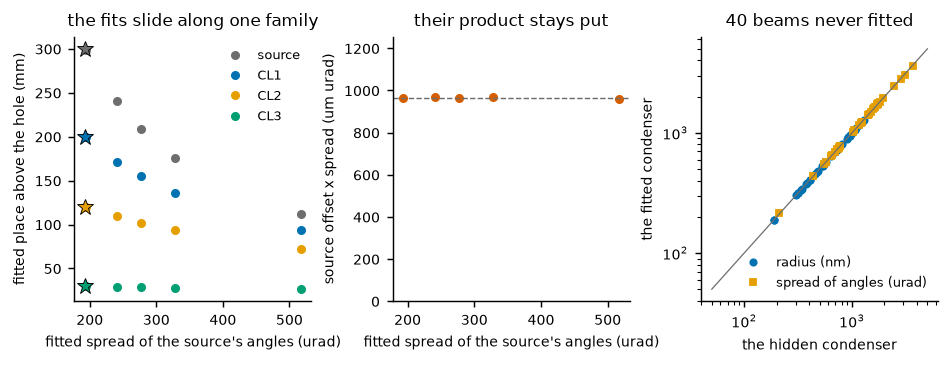

In [10]:
runs = study["the ladder"]
figure, (left, middle, right) = plt.subplots(1, 3, figsize=(7.2, 2.7), constrained_layout=True)
spread = np.array([np.exp(r["numbers"]["log_source_spread"]) for r in runs]) * 1e6
places = np.array([r["places"] for r in runs])
for column, (name, colour) in enumerate([("source", GREY), ("CL1", BLUE), ("CL2", ORANGE), ("CL3", GREEN)]):
    left.plot(spread, places[:, column], "o", color=colour, ms=4, label=name)
    left.plot(SOURCE["spread"] * 1e6, above_the_hole(TRUTH)[column], "*", color=colour, ms=9, mec="black", mew=0.5)
left.set(xlabel="fitted spread of the source's angles (urad)", ylabel="fitted place above the hole (mm)", title="the fits slide along one family")
left.legend(frameon=False, fontsize=7)
position = np.array([np.hypot(*r["numbers"]["source_x"]) for r in runs]) * 1e6
middle.plot(spread, position * spread, "o", color=RED, ms=4)
middle.axhline(abs(SOURCE["x0"]) * SOURCE["spread"] * 1e12, color=GREY, lw=0.8, ls="--")
middle.set(xlabel="fitted spread of the source's angles (urad)", ylabel="source offset x spread (um urad)",
           title="their product stays put", ylim=(0, 1.3 * abs(SOURCE["x0"]) * SOURCE["spread"] * 1e12))
best = runs[0]["numbers"]
r, a, *_ = [np.asarray(v) for v in model_beams(best, jnp.array(KEPT[:, :3]), jnp.array(KEPT[:, 3].astype(int) - 1))]
right.loglog(KEPT_TRUE["radius"] * 1e9, r * 1e9, "o", color=BLUE, ms=3.5, label="radius (nm)")
right.loglog(KEPT_TRUE["spread"] * 1e6, a * 1e6, "s", color=ORANGE, ms=3.5, label="spread of angles (urad)")
span = [50, 5000]
right.loglog(span, span, color=GREY, lw=0.7)
right.set(xlabel="the hidden condenser", ylabel="the fitted condenser", title="40 beams never fitted")
right.legend(frameon=False, fontsize=7)
plt.show()

**Figure 2.** Left: each fit of the ladder is a column of four points (stars: the truth). CL3 hardly moves; the
source, CL1 and CL2 land anywhere along one line, tied to the spread of angles the fit gives the source. Middle: along
that line the source's distance off the axis times its spread of angles stays the same, which is the family of
section 5. Right: one of those fitted condensers, asked for 40 beams it never saw.

**What the table shows.**

* **The fit works every time** on the ladder (54 settings) and on the first shorter one (46): chi2/dof is about 1,
  and the 40 kept-back beams come out to about 1 % in radius, spread and signal. A sixth recording of each, run
  outside this notebook, did too.
* **Pinned:** CL3's place (within a few mm), how far each lens turns the beam, the hole centres and the other holes'
  diameters.
* **Not pinned:** the places of the source, CL1 and CL2, and with them those lenses' strengths and the source's own
  size of angles. They are different in every recording and the beams are the same.
* **The smallest recording that worked every time is the 46-setting one, 92 frames.** With 32 settings the fit
  fails on most recordings (chi2/dof in the hundreds, the kept-back beams wrong). The information is not what runs
  out first: the stages of the fit need enough settings each to find their lens.

## 8. What to record

A script `record_condenser.py` would follow `record_predictor.py`'s condenser stage, with these stages.

| Stage | Settings | Frames kept |
|---|---|---|
| `alone` | CL1 at 3000, CL2 at 0; CL3 at 6 values about focus; 40 um hole | 12 |
| `cl2` | CL1 at 3000; CL2 at 2 values; CL3 at 4 values about focus | 16 |
| `cl1` | CL2 at 0; CL1 at 2 or 3 values; CL3 at 4 values about focus | 16 to 24 |
| `both` | 3 or 4 pairs of CL1 and CL2; CL3 at 4 values about focus | 24 to 32 |
| `holes` | five of the settings above with the 150 um and 70 um holes | 24 |
| kept back | other lens values, never fitted | as many as wanted |

In all 92 to 108 frames, and a search for focus (not kept) at each pair of CL1 and CL2 and each hole.

* **No kicks.** Changing a condenser lens moves the beam by itself, and where it lands is the measurement.
* **Each setting, two frames:** a magnification row where the beam is 8 to 100 px in rms radius, and a camera length
  where the pattern is. The screen camera where it fits; the Merlin for spreads under 0.4 mrad.
* **From below.** CL1, CL2 and CL3 each come to their value from below, and so do the projection lenses at
  every change between the row and the camera length. CL2's off is the console's 0, which cannot be reached from
  below: come down to it from the same value every time. How far below is enough has to be measured: on the
  virtual NEOARM 2000 units is not (the same setting then depends on the ones before it), 8000 is.
* **Centring and tracking.** The beam is centred with CLA1 in the magnification row and with CLA2 at the camera
  length, as in `record_predictor.py`, and every frame's CLA1, CLA2 and PLA values go in the table. Where the beam
  really was is what the camera saw minus what the deflectors added, in metres and radians. The fit needs this:
  where the beam lands as the lenses change is what gives the source's position, the hole centres and the lenses'
  turning.
* **PLA neutral** throughout.
* **Units.** Metres come from the grating image and radians from the gold rings. The projection lens model is not
  used.
* **The hole's diameter is the ruler.** The 40 um hole's nominal diameter sets every length. If it is 2 % off, so is
  every length.

## 9. What this does not cover

* **Where CL1, CL2 and the source are.** Shown above: not from this kind of recording. It needs something known above
  CL1, or a far longer recording, or the lens bodies' thickness from elsewhere.
* **The fixed part below the hole comes out as one lens between two gaps.** Those are not the real places of the
  corrector, CM and the objective's front field, which never change here. Changing CM would be the next ladder.
* **A second high tension.** Section 2 gives an argument that it would help only through the lens bodies' thickness.
  It was not simulated.
* **The lenses share one axis** in the hidden condenser, and the beam is a round Gaussian cut by a round hole. A real
  source is not Gaussian, real lenses sit off each other's axes, and a real hole is not perfectly round.
* **Lens strength follows the simple law** from 3000 to 60000 DAC units, with no saturation and nothing left over at
  0. CL2 at 0 may still have a little field.
* **The measurement itself.** Frames are not rendered here: the beam's radius, spread, signal and middle are taken as
  read from them with the stated scatter. Going through the virtual NEOARM's PyJEM imitation and real frames is the
  next step, as it was for the projection lenses.
* **Focus is taken from the hidden condenser.** The script has to find it with search frames.
* **Aberrations, the corrector's multipoles, the gun's own lens and deflectors** are not modelled.